# Clustering KPI Karyawan (K-Means Clustering)

- **Dataset** : `Report.csv`  
- **Metode** : K-Means Clustering dengan MinMax Scaling  
- **Evaluasi** : Elbow Method, Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz  


## 1. Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score,
    calinski_harabasz_score,
)
import joblib, os, json
from collections import Counter

print('Library berhasil diimport')

Library berhasil diimport


## 2. Load data

In [2]:
# ── Load ─────────────────────────────────────────────────────
df = pd.read_csv('Report.csv')

# ── Auto-rename: 'Tanggal Visit' (nama lama) → 'Report Product' (nama baru) ──
# Supaya proses modeling tetap jalan baik CSV sumbernya masih pakai
# header lama 'Tanggal Visit' maupun sudah pakai header baru 'Report Product'.
if 'Tanggal Visit' in df.columns and 'Report Product' not in df.columns:
    df = df.rename(columns={'Tanggal Visit': 'Report Product'})
    print("Kolom 'Tanggal Visit' otomatis di-rename menjadi 'Report Product'")

print(f'Raw data: {df.shape[0]:,} baris, {df.shape[1]} kolom')
print('Kolom tersedia:', df.columns.tolist())

Kolom 'Tanggal Visit' otomatis di-rename menjadi 'Report Product'
Raw data: 643,310 baris, 32 kolom
Kolom tersedia: ['Report Product', 'Region', 'Area', 'Username', 'Nama Karyawan', 'Role', 'Kode Store', 'Nama Store', 'Channel', 'Subchannel', 'Account', 'Kategori', 'Brand', 'Kode Produk', 'Nama Produk', 'Is Available', 'Reason SKU Not Available', 'Stock Regular', 'Stock COC', 'Stock Display', 'Standard Stock', 'Compliance', 'Facing', 'Facing COC', 'Is FIFO/FEFO', 'Expire Date', 'Is Price Tag Available', 'Price Normal', 'Price Promo', 'Suggest Order', 'Selling In', 'Selling Out']


In [3]:
# ── Pilih kolom — termasuk Nama Store & Role ─────────────────
KOLOM_WAJIB = [
    'Username', 'Report Product',
    'Area', 'Nama Karyawan', 'Region', 'Role',
    'Nama Store',
    'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available',
]

# Hanya ambil kolom yang benar-benar ada di file
kolom_ada    = [c for c in KOLOM_WAJIB if c in df.columns]
kolom_hilang = [c for c in KOLOM_WAJIB if c not in df.columns]

if kolom_hilang:
    print(f'Kolom tidak ditemukan (akan diisi "-"): {kolom_hilang}')
    for c in kolom_hilang:
        df[c] = '-'

df = df[KOLOM_WAJIB].copy()
print(f'\nKolom yang dipakai: {df.columns.tolist()}')


Kolom yang dipakai: ['Username', 'Report Product', 'Area', 'Nama Karyawan', 'Region', 'Role', 'Nama Store', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']


In [4]:
#  Tipe data dasar 
df['Report Product'] = pd.to_datetime(df['Report Product'], errors='coerce')
df['Facing']        = pd.to_numeric(df['Facing'], errors='coerce').fillna(0).clip(lower=0)
df['Is FIFO/FEFO']           = df['Is FIFO/FEFO'].astype(str).str.upper().str.strip()
df['Is Price Tag Available'] = df['Is Price Tag Available'].astype(str).str.upper().str.strip()

#  FILTER 1 — Username format ID-XX 
n_sebelum = len(df)
df        = df[df['Username'].astype(str).str.match(r'^ID-', na=False)].copy()
print(f'Baris dibuang (Username bukan ID-xxx) : {n_sebelum - len(df):,}')
print(f'Baris tersisa (karyawan valid)        : {len(df):,}')

#  FILTER 2 — Buang FIFO/FEFO = '-1' (sentinel data kotor) 
mask_invalid = df['Is FIFO/FEFO'] == '-1'
print(f'Baris dengan FIFO/FEFO=-1 dibuang     : {mask_invalid.sum():,}')
df = df[~mask_invalid].copy()

# cek nilai unik sebelum normalisasi 
# Ini penting untuk mendeteksi format pengisian data yang berbeda
print()
print('=== Nilai unik FIFO/FEFO (sebelum normalisasi) ===')
print(df['Is FIFO/FEFO'].value_counts(dropna=False).to_dict())
print()
print('=== Nilai unik Price Tag (sebelum normalisasi) ===')
print(df['Is Price Tag Available'].value_counts(dropna=False).to_dict())

#  FILTER 3 — Normalisasi KPI dengan mapping yang diperluas 
# PERBAIKAN: mapping mencakup semua format pengisian yang umum.
# Format YA  : 'YA', '1', 'TRUE', 'YES'
# Format TIDAK: 'TIDAK', '0', 'FALSE', 'NO', 'N/A', 'TIDAK ADA'
# Nilai lain (kosong, nan, dll.) → TIDAK (dianggap tidak dilakukan)

MAP_YA    = {'YA', '1', 'TRUE', 'YES'}
MAP_TIDAK = {'TIDAK', '0', 'FALSE', 'NO', 'N/A', 'NA', 'TIDAK ADA'}

def normalize_kpi(val: str) -> str:
    v = str(val).upper().strip()
    if v in MAP_YA:
        return 'YA'
    # Apapun sisanya (termasuk TIDAK, 0, false, nan, kosong) → TIDAK
    return 'TIDAK'

df['Is FIFO/FEFO']           = df['Is FIFO/FEFO'].apply(normalize_kpi)
df['Is Price Tag Available'] = df['Is Price Tag Available'].apply(normalize_kpi)

print()
print('=== Distribusi SETELAH normalisasi ===')
fifo_dist = df['Is FIFO/FEFO'].value_counts().to_dict()
pt_dist   = df['Is Price Tag Available'].value_counts().to_dict()
print(f'Distribusi Is FIFO/FEFO  : {fifo_dist}')
print(f'Distribusi Price Tag     : {pt_dist}')
print(f'Facing min / max         : {df["Facing"].min()} / {df["Facing"].max()}')

# Peringatan jika salah satu KPI masih 0% YA
for col, dist in [('FIFO/FEFO', fifo_dist), ('Price Tag', pt_dist)]:
    pct_ya = dist.get('YA', 0) / sum(dist.values()) * 100
    if pct_ya == 0:
        print(f'\n  WARNING: {col} = 0% YA di seluruh data!')
        print(f'   Kemungkinan penyebab:')
        print(f'   1. Periode data terlalu sempit (karyawan belum sempat mengisi)')
        print(f'   2. Format nilai di CSV bukan YA/TIDAK/1/0/True/False')
        print(f'   3. Kolom ini memang tidak diisi di lapangan')
    elif pct_ya < 5:
        print(f'\n  WARNING: {col} hanya {pct_ya:.1f}% YA — sangat rendah.')
        print(f'   Fitur ini mungkin tidak diskriminatif untuk clustering.')


Baris dibuang (Username bukan ID-xxx) : 262
Baris tersisa (karyawan valid)        : 643,048
Baris dengan FIFO/FEFO=-1 dibuang     : 0

=== Nilai unik FIFO/FEFO (sebelum normalisasi) ===
{'TIDAK': 316049, 'YA': 313035, nan: 13964}

=== Nilai unik Price Tag (sebelum normalisasi) ===
{'TIDAK': 317017, 'YA': 312067, nan: 13964}

=== Distribusi SETELAH normalisasi ===
Distribusi Is FIFO/FEFO  : {'TIDAK': 330013, 'YA': 313035}
Distribusi Price Tag     : {'TIDAK': 330981, 'YA': 312067}
Facing min / max         : 0.0 / 730.0


## 3. Normalisasi Facing

Nilai `Facing` di data mentah bisa berupa **hitungan absolut** (jumlah facing produk), bukan rasio 0–1.  
Nilai > 1.0 (atau > 100%) adalah indikasi data belum dinormalisasi.

**Strategi yang dipakai:**  
Clip ke **persentil ke-95** antar karyawan, lalu scale ke 0–1.  
Ini mencegah outlier ekstrem mendominasi clustering tanpa kehilangan variasi antar karyawan.

In [5]:
# ── Cek apakah Facing perlu dinormalisasi ────────────────────
facing_max  = df['Facing'].max()
facing_p95  = df['Facing'].quantile(0.95)
facing_mean = df['Facing'].mean()

print('=== Statistik Facing (sebelum normalisasi) ===')
print(df['Facing'].describe().round(3))
print(f'\nPersentil 95 : {facing_p95:.3f}')

FACING_PERLU_NORMALISASI = facing_max > 1.0
print(f'\nFacing > 1.0 terdeteksi : {FACING_PERLU_NORMALISASI}')
if FACING_PERLU_NORMALISASI:
    print('  → Akan dinormalisasi menggunakan clip persentil 95 + scale 0-1')
else:
    print('  → Facing sudah dalam rentang 0-1, tidak perlu normalisasi tambahan')

=== Statistik Facing (sebelum normalisasi) ===
count    643048.000
mean          1.619
std          11.457
min           0.000
25%           0.000
50%           0.000
75%           1.000
max         730.000
Name: Facing, dtype: float64

Persentil 95 : 2.000

Facing > 1.0 terdeteksi : True
  → Akan dinormalisasi menggunakan clip persentil 95 + scale 0-1


Clip range    : [0.00, 2.00]
Facing_norm   : min=0.000, max=1.000, mean=0.177


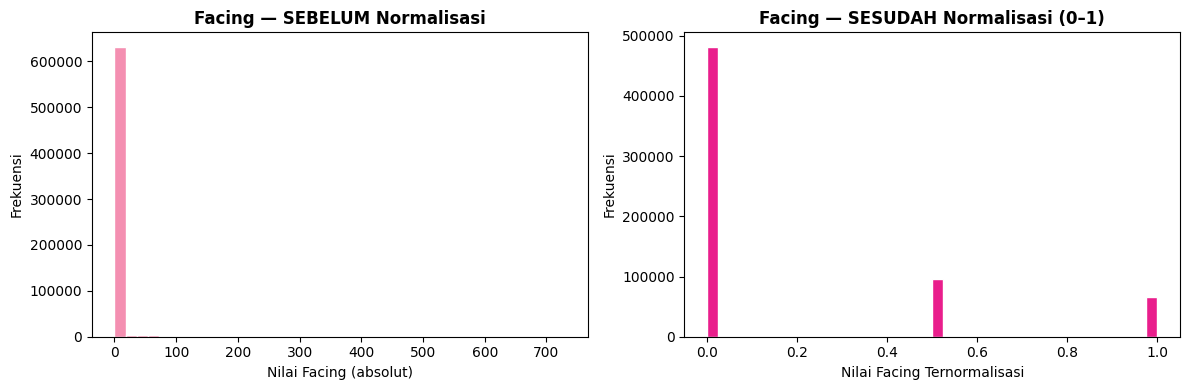


 Kolom Facing diganti dengan versi ternormalisasi (0-1)
     FIFO/FEFO dan Price Tag TIDAK berubah — masih dalam format YA/TIDAK


In [6]:
# ── Terapkan normalisasi Facing (opsional) ──────────────────
# Normalisasi ini HANYA mengubah kolom 'Facing' di df (data row).
# Kolom 'Is FIFO/FEFO' dan 'Is Price Tag Available' TIDAK terpengaruh.
# Normalisasi dilakukan di level row agar nilai rata-rata per karyawan
# (yang dihitung saat groupby) tetap berada di rentang 0-1.

if FACING_PERLU_NORMALISASI:
    p95 = df['Facing'].quantile(0.95)
    p05 = df['Facing'].quantile(0.05)

    if p95 > p05:
        df['Facing_norm'] = (
            df['Facing'].clip(lower=p05, upper=p95) - p05
        ) / (p95 - p05)
    else:
        # Facing hampir konstan — skala ke 0.5 agar tidak hilang
        df['Facing_norm'] = 0.5
        print('  Facing hampir konstan antar karyawan — di-set ke 0.5 (netral)')

    print(f'Clip range    : [{p05:.2f}, {p95:.2f}]')
    print(f'Facing_norm   : min={df["Facing_norm"].min():.3f}, '
          f'max={df["Facing_norm"].max():.3f}, '
          f'mean={df["Facing_norm"].mean():.3f}')

    # Visualisasi sebelum vs sesudah
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(df['Facing'],      bins=40, color='#F48FB1', edgecolor='white')
    axes[0].set_title('Facing — SEBELUM Normalisasi', fontweight='bold')
    axes[0].set_xlabel('Nilai Facing (absolut)')
    axes[0].set_ylabel('Frekuensi')

    axes[1].hist(df['Facing_norm'], bins=40, color='#E91E8C', edgecolor='white')
    axes[1].set_title('Facing — SESUDAH Normalisasi (0–1)', fontweight='bold')
    axes[1].set_xlabel('Nilai Facing Ternormalisasi')
    axes[1].set_ylabel('Frekuensi')

    plt.tight_layout()
    plt.savefig('plot_facing_normalisasi.png', dpi=150, bbox_inches='tight')
    plt.show()

    # Ganti kolom Facing dengan versi ternormalisasi
    df['Facing'] = df['Facing_norm']
    df.drop(columns=['Facing_norm'], inplace=True)
    print('\n Kolom Facing diganti dengan versi ternormalisasi (0-1)')
    print('     FIFO/FEFO dan Price Tag TIDAK berubah — masih dalam format YA/TIDAK')
else:
    print(' Facing sudah dalam rentang 0-1, tidak perlu normalisasi tambahan')


## 4. Groupby per Username & Buat Report_Clean

In [7]:
# ── Groupby per Username untuk clustering ───────────────────
df_grouped = (
    df.groupby('Username')
    .agg(
        Facing      = ('Facing',                 'mean'),
        Is_FIFO     = ('Is FIFO/FEFO',           lambda x: (x == 'YA').mean()),
        Is_PriceTag = ('Is Price Tag Available', lambda x: (x == 'YA').mean()),
        visit_count = ('Report Product',          'count'),
    )
    .rename(columns={
        'Is_FIFO'    : 'Is FIFO/FEFO',
        'Is_PriceTag': 'Is Price Tag Available',
    })
    .reset_index()
    .fillna(0)
)

# ── employee_info — termasuk Role ───────────────────────────
info_base_cols = ['Username', 'Nama Karyawan', 'Area', 'Region', 'Role']
employee_info  = df[info_base_cols].drop_duplicates('Username').reset_index(drop=True)

# ── Nama Store: kumpulkan semua toko unik per karyawan ──────
store_agg = (
    df.groupby('Username')['Nama Store']
    .apply(lambda x: ' | '.join(sorted(x.dropna().astype(str)
                                        .str.strip()
                                        .replace('', pd.NA)
                                        .dropna()
                                        .unique())))
    .reset_index()
    .rename(columns={'Nama Store': 'Daftar Nama Store'})
)
store_count = (
    df.groupby('Username')['Nama Store']
    .nunique()
    .reset_index()
    .rename(columns={'Nama Store': 'Jumlah Store Unik'})
)

employee_info = (
    employee_info
    .merge(store_agg,   on='Username', how='left')
    .merge(store_count, on='Username', how='left')
)

print(f'Total karyawan valid untuk clustering : {len(df_grouped)}')
print(f'employee_info kolom                   : {employee_info.columns.tolist()}')
df_grouped.describe().round(3)

Total karyawan valid untuk clustering : 80
employee_info kolom                   : ['Username', 'Nama Karyawan', 'Area', 'Region', 'Role', 'Daftar Nama Store', 'Jumlah Store Unik']


,Facing,Is FIFO/FEFO,Is Price Tag Available,visit_count
count,80.000,80.000,80.000,80.00
mean,0.195,0.507,0.505,8038.10
std,0.074,0.152,0.156,3394.43
min,0.059,0.202,0.101,710.00
25%,0.147,0.422,0.417,6182.25
50%,0.179,0.464,0.463,8037.50
75%,0.229,0.536,0.536,9449.25
max,0.462,0.930,0.930,20375.00


In [8]:
# ── Cek variasi fitur (deteksi fitur tidak informatif) ───────
feature_cols_all = ['visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']

print('=== Cek Variasi Fitur ===')
print(f'{"Fitur":<28} {"Mean":>8} {"Std":>8} {"% Nol":>8}  {"% YA (KPI)":>12}  Status')
print('-' * 75)

ACTIVE_FEATURES = []
excluded        = []

for col in feature_cols_all:
    std      = df_grouped[col].std()
    mean     = df_grouped[col].mean()
    pct_zero = (df_grouped[col] == 0).mean() * 100
    pct_ya   = mean * 100  # untuk KPI (nilai 0-1), mean = proporsi YA

    if std < 0.001:
        status = ' EXCLUDE — tidak bervariasi sama sekali'
        excluded.append(col)
    elif col != 'visit_count' and pct_zero > 95:
        # Threshold 95% (bukan 90%) — lebih konservatif
        # Fitur KPI dengan >95% nol tidak berguna untuk clustering
        status = f' EXCLUDE — {pct_zero:.0f}% bernilai 0 (hampir tidak ada YA)'
        excluded.append(col)
    else:
        status = ' OK'
        ACTIVE_FEATURES.append(col)

    # Tampilkan persen YA hanya untuk kolom KPI
    ya_info = f'{pct_ya:>11.1f}%' if col != 'visit_count' else f'{"(N/A)":>12}'
    print(f'{col:<28} {mean:>8.3f} {std:>8.3f} {pct_zero:>7.1f}%  {ya_info}  {status}')

print()
if excluded:
    print(f'  Fitur di-exclude dari clustering  : {excluded}')
    print()
    print('  Penjelasan:')
    for col in excluded:
        pct_zero = (df_grouped[col] == 0).mean() * 100
        pct_ya   = df_grouped[col].mean() * 100
        if col != 'visit_count':
            print(f'  [{col}]')
            print(f'    - Hanya {pct_ya:.1f}% kunjungan yang memiliki nilai YA')
            print(f'    - Fitur ini tidak membedakan antar karyawan secara bermakna')
            print(f'    - Kemungkinan: data belum lengkap ATAU memang 0 di lapangan')
else:
    print(' Semua fitur informatif — tidak ada yang di-exclude')

print(f'\nFitur aktif untuk clustering : {ACTIVE_FEATURES}')

if len(ACTIVE_FEATURES) < 2:
    raise ValueError(' Terlalu sedikit fitur informatif. Periksa kelengkapan data.')

# ── Ringkasan: berapa persen data YA per KPI ─────────────────
print()
print('=== Ringkasan KPI Compliance (keseluruhan dataset) ===')
for col in ['Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']:
    if col in df_grouped.columns:
        mean_val = df_grouped[col].mean()
        print(f'  {col:<30}: {mean_val*100:.1f}% rata-rata compliance')


=== Cek Variasi Fitur ===
Fitur                            Mean      Std    % Nol    % YA (KPI)  Status
---------------------------------------------------------------------------
visit_count                  8038.100 3394.430     0.0%         (N/A)   OK
Facing                          0.195    0.074     0.0%         19.5%   OK
Is FIFO/FEFO                    0.507    0.152     0.0%         50.7%   OK
Is Price Tag Available          0.505    0.156     0.0%         50.5%   OK

 Semua fitur informatif — tidak ada yang di-exclude

Fitur aktif untuk clustering : ['visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']

=== Ringkasan KPI Compliance (keseluruhan dataset) ===
  Facing                        : 19.5% rata-rata compliance
  Is FIFO/FEFO                  : 50.7% rata-rata compliance
  Is Price Tag Available        : 50.5% rata-rata compliance


In [9]:
# ── Buat Report_Clean — satu baris per karyawan ─────────────
# Gabungkan: employee_info + visit_count + rata-rata KPI + Daftar Store
visit_count_ser = df_grouped[['Username', 'visit_count']]

df_clean = (
    employee_info
    .merge(visit_count_ser, on='Username', how='left')
)

# Tambahkan rata-rata KPI mentah (sebelum di-groupby scaled)
kpi_agg = (
    df.groupby('Username')
    .agg(
        Facing_avg      = ('Facing',                 'mean'),
        FIFO_pct        = ('Is FIFO/FEFO',           lambda x: round((x=='YA').mean()*100, 1)),
        PriceTag_pct    = ('Is Price Tag Available', lambda x: round((x=='YA').mean()*100, 1)),
    )
    .reset_index()
)
df_clean = df_clean.merge(kpi_agg, on='Username', how='left')
df_clean['Facing_avg'] = df_clean['Facing_avg'].apply(lambda x: round(x * 100, 1))

# ── Rename kolom hasil rename sebelumnya (dulu 'Tanggal Visit') → 'Report Product' ──
df_clean = df_clean.rename(columns={
    'visit_count'        : 'Report Product',
    'Facing_avg'         : 'Facing (%)',
    'FIFO_pct'           : 'FIFO/FEFO (%)',
    'PriceTag_pct'       : 'Price Tag (%)',
    'Daftar Nama Store'  : 'Nama Store',
    'Jumlah Store Unik'  : 'Jumlah Store',
})

# Urutkan kolom agar mudah dibaca
col_order = [
    'Username', 'Nama Karyawan', 'Role', 'Area', 'Region',
    'Report Product', 'Facing (%)', 'FIFO/FEFO (%)', 'Price Tag (%)',
    'Jumlah Store', 'Nama Store',
]
col_order = [c for c in col_order if c in df_clean.columns]
df_clean  = df_clean[col_order]

df_clean.to_excel('Report_Clean.xlsx', index=False)
print(f' Report_Clean.xlsx disimpan: {df_clean.shape[0]} baris, {df_clean.shape[1]} kolom')
print(f'   Kolom: {df_clean.columns.tolist()}')

# ── Auto-download Report_Clean.xlsx ──────────────────────────
try:
    from google.colab import files as _colab_files
    _colab_files.download('Report_Clean.xlsx')
    print("'Report_Clean.xlsx' otomatis ter-download (Google Colab).")
except ImportError:
    print("Auto-download browser hanya aktif di Google Colab.")
    print(f"Di Jupyter lokal, file tersimpan di: {os.path.abspath('Report_Clean.xlsx')}")

df_clean.head(5)

 Report_Clean.xlsx disimpan: 80 baris, 11 kolom
   Kolom: ['Username', 'Nama Karyawan', 'Role', 'Area', 'Region', 'Report Product', 'Facing (%)', 'FIFO/FEFO (%)', 'Price Tag (%)', 'Jumlah Store', 'Nama Store']
Auto-download browser hanya aktif di Google Colab.
Di Jupyter lokal, file tersimpan di: c:\Skripsi TA\code skripsi\Report_Clean.xlsx


,Username,Nama Karyawan,Role,Area,Region,Report Product,Facing (%),FIFO/FEFO (%),Price Tag (%),Jumlah Store,Nama Store
0,ID-SA000648,JANELCO RIFDY HURSEPUNY,MD MIX,AMBON,MALUKU,8202,16.1,35.4,35.4,77,AIKO-PASAR RUMAH TIGA-AMBON | AL BAGIR-BATU ME...
1,ID-NB000256,MUHAMMAD ANDRI SEFTIANA,MD MIX,LOMBOK,BALI NUSRA,7263,15.0,46.9,46.9,102,ADA MART | APRIONO | BIG M SENGGIGI | CEMERLAN...
2,ID-BA010042,DEDI HERMAWAN,MD MIX,DENPASAR,BALI NUSRA,16336,9.8,48.5,48.5,151,ARYS MIKRO PRATAMA | BELITUNG GROSIR | BIG M B...
3,ID-BA000832,KADEK AGUS SATYA NUGRAHA,MD MM,DENPASAR,BALI NUSRA,15738,9.5,41.1,41.1,146,ADI JAYA MUNGGU | ARTHA SEDANA | ARYS MIKRO BA...
4,ID-SN001032,RIFKI WIRAWAN,MD MIX,MAKASSAR,SULAWESI SELATAN,2694,18.4,50.9,50.9,50,AHDIAH MART | AMALIA JAYA | BIG MM PENGAYOMAN ...


## 5. Distribusi Data — Sebelum & Sesudah Scaling

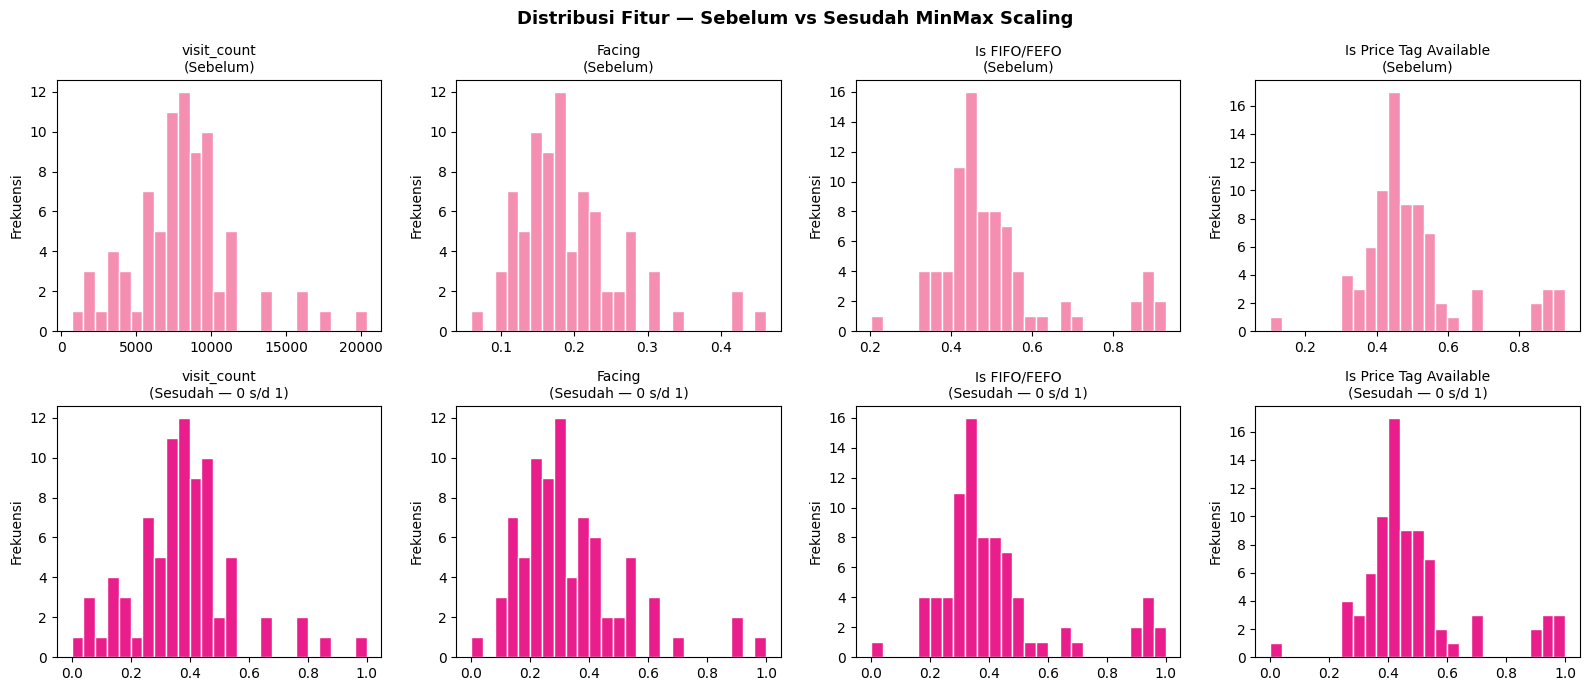

Statistik setelah scaling:
  visit_count                   : min=0.000  max=1.000  mean=0.373  std=0.172
  Facing                        : min=0.000  max=1.000  mean=0.336  std=0.183
  Is FIFO/FEFO                  : min=0.000  max=1.000  mean=0.420  std=0.208
  Is Price Tag Available        : min=0.000  max=1.000  mean=0.487  std=0.187


In [10]:
X = df_grouped[ACTIVE_FEATURES].values

scaler   = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

n_feat = len(ACTIVE_FEATURES)
fig, axes = plt.subplots(2, n_feat, figsize=(4 * n_feat, 7))
if n_feat == 1:
    axes = axes.reshape(2, 1)
fig.suptitle('Distribusi Fitur — Sebelum vs Sesudah MinMax Scaling', fontsize=13, fontweight='bold')

for i, col in enumerate(ACTIVE_FEATURES):
    axes[0, i].hist(X[:, i],        bins=25, color='#F48FB1', edgecolor='white')
    axes[0, i].set_title(f'{col}\n(Sebelum)', fontsize=10)
    axes[0, i].set_ylabel('Frekuensi')

    axes[1, i].hist(X_scaled[:, i], bins=25, color='#E91E8C', edgecolor='white')
    axes[1, i].set_title(f'{col}\n(Sesudah — 0 s/d 1)', fontsize=10)
    axes[1, i].set_ylabel('Frekuensi')

plt.tight_layout()
plt.savefig('plot_distribusi.png', dpi=150, bbox_inches='tight')
plt.show()

print('Statistik setelah scaling:')
for i, col in enumerate(ACTIVE_FEATURES):
    print(f'  {col:<30}: min={X_scaled[:,i].min():.3f}  '
          f'max={X_scaled[:,i].max():.3f}  '
          f'mean={X_scaled[:,i].mean():.3f}  '
          f'std={X_scaled[:,i].std():.3f}')

## 6. Menentukan K Optimal — Elbow, Silhouette, Davies-Bouldin, Calinski-Harabasz

In [11]:
K_MAX       = min(10, len(df_grouped) - 1)
K_RANGE     = range(2, K_MAX + 1)

inertia_list = []
sil_list     = []
dbi_list     = []
ch_list      = []

for k in K_RANGE:
    km     = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertia_list.append(km.inertia_)
    sil_list.append(silhouette_score(X_scaled, labels))
    dbi_list.append(davies_bouldin_score(X_scaled, labels))
    ch_list.append(calinski_harabasz_score(X_scaled, labels))

# ── Majority voting: Silhouette + DBI + CH ──────────────────
best_sil_k = list(K_RANGE)[sil_list.index(max(sil_list))]
best_dbi_k = list(K_RANGE)[dbi_list.index(min(dbi_list))]
best_ch_k  = list(K_RANGE)[ch_list.index(max(ch_list))]

votes      = [best_sil_k, best_dbi_k, best_ch_k]
vote_count = Counter(votes)
BEST_K     = vote_count.most_common(1)[0][0]

# Tie-break → Silhouette
if vote_count.most_common(1)[0][1] == 1:
    BEST_K    = best_sil_k
    tie_note  = '(tie-break → Silhouette)'
else:
    tie_note  = '(majority voting)'

print('=== Pemilihan K Optimal ===')
print(f'  Silhouette terbaik       : k={best_sil_k}  ({max(sil_list):.4f})')
print(f'  Davies-Bouldin terbaik   : k={best_dbi_k}  ({min(dbi_list):.4f})')
print(f'  Calinski-Harabasz terbaik: k={best_ch_k}  ({max(ch_list):.2f})')
print(f'  Hasil voting             : {votes}')
print(f'  (terpilih) K optimal             : k={BEST_K}  {tie_note}')

=== Pemilihan K Optimal ===
  Silhouette terbaik       : k=2  (0.6179)
  Davies-Bouldin terbaik   : k=2  (0.5409)
  Calinski-Harabasz terbaik: k=2  (89.61)
  Hasil voting             : [2, 2, 2]
  (terpilih) K optimal             : k=2  (majority voting)


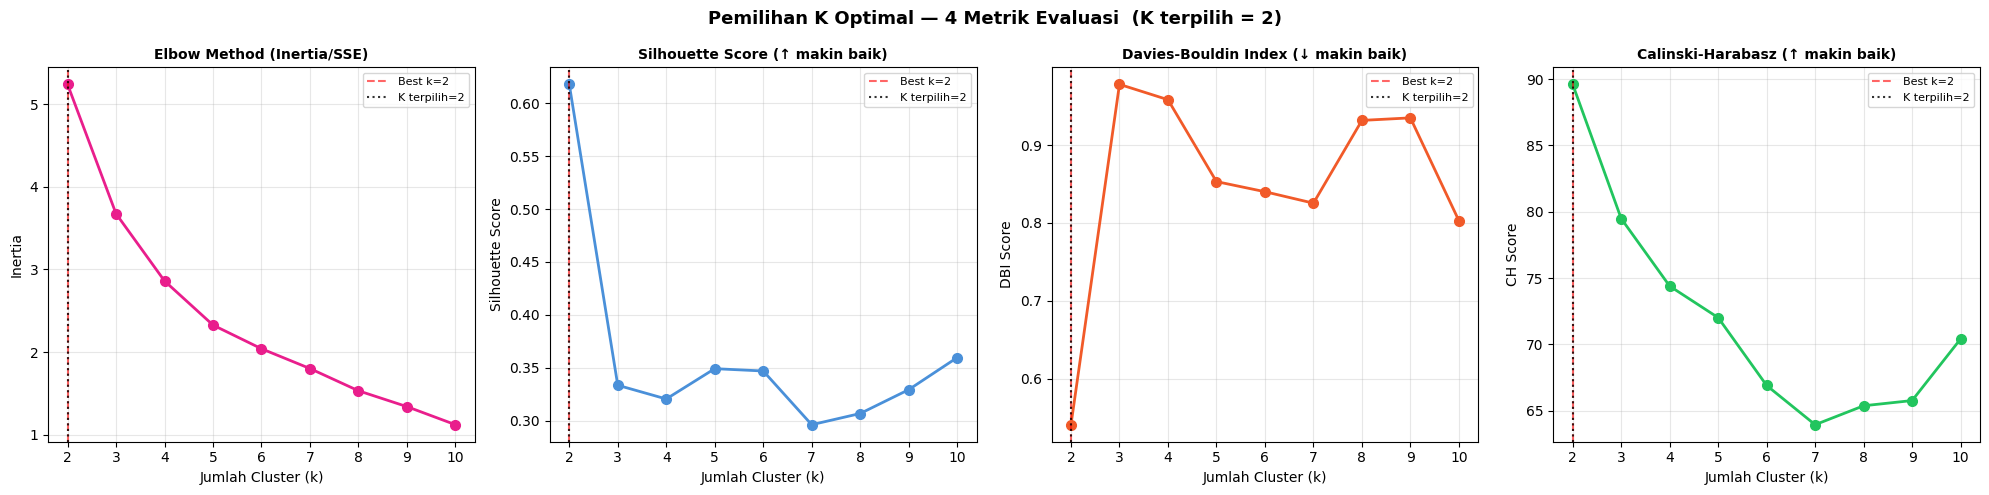


=== Tabel Evaluasi per K ===
 k  Inertia  Silhouette  Davies-Bouldin  Calinski-Harabasz Terpilih
 2     5.24      0.6179          0.5409              89.61        ✅
 3     3.68      0.3334          0.9780              79.49         
 4     2.86      0.3204          0.9583              74.40         
 5     2.33      0.3491          0.8531              72.02         
 6     2.04      0.3469          0.8401              66.91         
 7     1.80      0.2961          0.8254              63.95         
 8     1.53      0.3067          0.9317              65.38         
 9     1.34      0.3292          0.9349              65.77         
10     1.12      0.3596          0.8029              70.42         


In [12]:
# ── Plot 4 metrik ────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle(f'Pemilihan K Optimal — 4 Metrik Evaluasi  (K terpilih = {BEST_K})',
             fontsize=13, fontweight='bold')

plots = [
    (inertia_list, best_sil_k, 'Elbow Method (Inertia/SSE)',              '#E91E8C', 'Inertia',              False),
    (sil_list,     best_sil_k, 'Silhouette Score (↑ makin baik)',         '#4A90D9', 'Silhouette Score',     False),
    (dbi_list,     best_dbi_k, 'Davies-Bouldin Index (↓ makin baik)',     '#F15A29', 'DBI Score',            False),
    (ch_list,      best_ch_k,  'Calinski-Harabasz (↑ makin baik)',        '#22c55e', 'CH Score',             False),
]
best_ks = [best_sil_k, best_sil_k, best_dbi_k, best_ch_k]

for ax, (vals, bk, title, color, ylabel, _), bk2 in zip(axes, plots, best_ks):
    ax.plot(K_RANGE, vals, 'o-', color=color, linewidth=2, markersize=7)
    ax.axvline(x=bk2, color='red', linestyle='--', alpha=0.6, label=f'Best k={bk2}')
    ax.axvline(x=BEST_K, color='black', linestyle=':', alpha=0.8, label=f'K terpilih={BEST_K}')
    ax.set_title(title, fontweight='bold', fontsize=10)
    ax.set_xlabel('Jumlah Cluster (k)')
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    ax.set_xticks(list(K_RANGE))

plt.tight_layout()
plt.savefig('plot_pemilihan_k.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Tabel evaluasi ───────────────────────────────────────────
eval_df = pd.DataFrame({
    'k'                  : list(K_RANGE),
    'Inertia'            : [round(v, 2) for v in inertia_list],
    'Silhouette'         : [round(v, 4) for v in sil_list],
    'Davies-Bouldin'     : [round(v, 4) for v in dbi_list],
    'Calinski-Harabasz'  : [round(v, 2) for v in ch_list],
    'Terpilih'           : ['✅' if k == BEST_K else '' for k in K_RANGE],
})
print('\n=== Tabel Evaluasi per K ===')
print(eval_df.to_string(index=False))

In [13]:
kmeans_final = KMeans(
    n_clusters=BEST_K,
    init='k-means++',
    n_init=10,
    random_state=42
)

kmeans_final.fit(X_scaled)
centroid_df = pd.DataFrame(
    kmeans_final.cluster_centers_,
    columns=ACTIVE_FEATURES
)

# ubah index menjadi nama cluster
centroid_df.index = [
    f'Cluster {i}'
    for i in range(len(centroid_df))
]

print('\n=== KOORDINAT CENTROID (SKALA HASIL SCALING 0–1) ===')
display(centroid_df.round(3))

# versi lebih mudah dibaca (persen untuk KPI)
centroid_readable = centroid_df.copy()

for col in centroid_readable.columns:
    if col != 'visit_count':
        centroid_readable[col] = (
            centroid_readable[col] * 100
        ).round(1)

print('\n= PROFIL CENTROID =')
for idx, row in centroid_readable.iterrows():

    print(f'\n{idx}')

    for col in ACTIVE_FEATURES:

        if col == 'visit_count':
            print(f'  {col:<28}: {row[col]:.2f}')
        else:
            print(f'  {col:<28}: {row[col]:.1f}%')

print("Centroid akhir:")
print(kmeans_final.cluster_centers_)


=== KOORDINAT CENTROID (SKALA HASIL SCALING 0–1) ===


,visit_count,Facing,Is FIFO/FEFO,Is Price Tag Available
Cluster 0,0.398,0.291,0.353,0.428
Cluster 1,0.196,0.657,0.889,0.903



= PROFIL CENTROID =

Cluster 0
  visit_count                 : 0.40
  Facing                      : 29.1%
  Is FIFO/FEFO                : 35.3%
  Is Price Tag Available      : 42.8%

Cluster 1
  visit_count                 : 0.20
  Facing                      : 65.7%
  Is FIFO/FEFO                : 88.9%
  Is Price Tag Available      : 90.3%
Centroid akhir:
[[0.39788457 0.29069143 0.3525932  0.42797831]
 [0.19598271 0.65653163 0.88939815 0.90282145]]


## 7. Training Model Final — K Optimal

In [14]:
print(f'\n> Training KMeans k={BEST_K} (voting: sil={best_sil_k}, dbi={best_dbi_k}, ch={best_ch_k})')

kmeans_final = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
labels_final = kmeans_final.fit_predict(X_scaled)
df_grouped['cluster'] = labels_final


> Training KMeans k=2 (voting: sil=2, dbi=2, ch=2)


## 8. Auto-Label Cluster — Berdasarkan Profil Visit vs KPI

Label ditetapkan secara **otomatis** berdasarkan dua dimensi:
- **Visit** : frekuensi kunjungan rata-rata per cluster  
- **KPI**   : rata-rata Facing + FIFO/FEFO + Price Tag per cluster  

Setiap cluster dibandingkan terhadap **median** seluruh cluster → `High` atau `Low`  
Logika ini **identik** dengan `app.py` agar label konsisten di dashboard.

In [15]:
# ── Hitung visit_mean & kpi_mean per cluster ─────────────────
KPI_COLS = ['Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']
# Hanya gunakan KPI yang masuk ACTIVE_FEATURES
kpi_active = [c for c in KPI_COLS if c in ACTIVE_FEATURES]

agg_dict = {'visit_count': 'mean'}
for c in kpi_active:
    agg_dict[c] = 'mean'

cluster_stats = df_grouped.groupby('cluster').agg(agg_dict)
cluster_stats.columns = ['visit_mean'] + [f'{c}_mean' for c in kpi_active]
cluster_stats['kpi_mean'] = cluster_stats[[f'{c}_mean' for c in kpi_active]].mean(axis=1)

# ── Normalisasi 0-1 antar cluster (relatif) ──────────────────
def norm_series(s):
    mn, mx = s.min(), s.max()
    if mx == mn:
        return pd.Series([0.5] * len(s), index=s.index)
    return (s - mn) / (mx - mn)

cluster_stats['visit_norm'] = norm_series(cluster_stats['visit_mean'])
cluster_stats['kpi_norm']   = norm_series(cluster_stats['kpi_mean'])

print('=== Profil Cluster (sebelum labeling) ===')
print(cluster_stats[['visit_mean', 'kpi_mean', 'visit_norm', 'kpi_norm']].round(4))

=== Profil Cluster (sebelum labeling) ===
         visit_mean  kpi_mean  visit_norm  kpi_norm
cluster                                            
0            8534.4    0.3635         1.0       0.0
1            4564.0    0.6742         0.0       1.0


In [16]:
# ── Fungsi auto-label (identik dengan app.py) ────────────────
def auto_label_clusters(cs: pd.DataFrame) -> dict:
    """
    cs: DataFrame dengan kolom visit_mean, kpi_mean (sudah dinormalisasi 0-1)
    Return: {cluster_id: label_string}
    """
    v_med = cs['visit_mean'].median()
    k_med = cs['kpi_mean'].median()

    labels = {}
    for cid, row in cs.iterrows():
        v_tag = 'High Visit' if row['visit_mean'] >= v_med else 'Low Visit'
        k_tag = 'High KPI'   if row['kpi_mean']  >= k_med else 'Low KPI'
        labels[cid] = f'{v_tag} {k_tag}'

    # Resolve duplikat
    from collections import Counter
    count = Counter(labels.values())
    occur = Counter()
    final = {}
    for cid, lbl in labels.items():
        if count[lbl] > 1:
            occur[lbl] += 1
            final[cid] = f'{lbl} ({occur[lbl]})'
        else:
            final[cid] = lbl
    return final


def label_order_by_priority(labels: dict, cs: pd.DataFrame):
    priority = {
        'High Visit High KPI': 0,
        'High Visit Low KPI' : 1,
        'Low Visit High KPI' : 2,
        'Low Visit Low KPI'  : 3,
    }
    def sort_key(cid):
        lbl      = labels[cid]
        base_lbl = lbl.split(' (')[0]
        p        = priority.get(base_lbl, 9)
        visit    = cs.loc[cid, 'visit_mean']
        return (p, -visit)
    sorted_cids  = sorted(labels.keys(), key=sort_key)
    return [labels[cid] for cid in sorted_cids], sorted_cids


# ── Terapkan auto-label ───────────────────────────────────────
cs_for_label = cluster_stats[['visit_norm', 'kpi_norm']].rename(
    columns={'visit_norm': 'visit_mean', 'kpi_norm': 'kpi_mean'}
)

rank_labels                  = auto_label_clusters(cs_for_label)
label_order, ordered_cids    = label_order_by_priority(rank_labels, cs_for_label)
df_grouped['cluster_label']  = df_grouped['cluster'].map(rank_labels)

print('=== Mapping Cluster → Label ===')
for cid in ordered_cids:
    lbl   = rank_labels[cid]
    n_k   = (labels_final == cid).sum()
    v_m   = cluster_stats.loc[cid, 'visit_mean']
    kpi_m = cluster_stats.loc[cid, 'kpi_mean']
    print(f'  Cluster {cid} → {lbl:<22}  '
          f'({n_k} karyawan, visit_mean={v_m:.1f}, kpi_mean={kpi_m:.3f})')

print(f'\nUrutan tampilan dashboard: {label_order}')

=== Mapping Cluster → Label ===
  Cluster 0 → High Visit Low KPI      (70 karyawan, visit_mean=8534.4, kpi_mean=0.364)
  Cluster 1 → Low Visit High KPI      (10 karyawan, visit_mean=4564.0, kpi_mean=0.674)

Urutan tampilan dashboard: ['High Visit Low KPI', 'Low Visit High KPI']


## 9. Evaluasi Model

     EVALUASI MODEL K-MEANS  (k=2)
  Silhouette Score       : 0.6179  → Cukup baik
  Davies-Bouldin Index   : 0.5409  → Baik
  Calinski-Harabasz      : 89.61
  Inertia (SSE)          : 5.24
  Catatan:
  - Silhouette > 0.50 = cluster cukup terpisah
  - DBI < 1.0         = cluster tidak tumpang tindih
  - CH makin besar    = cluster makin kompak & terpisah


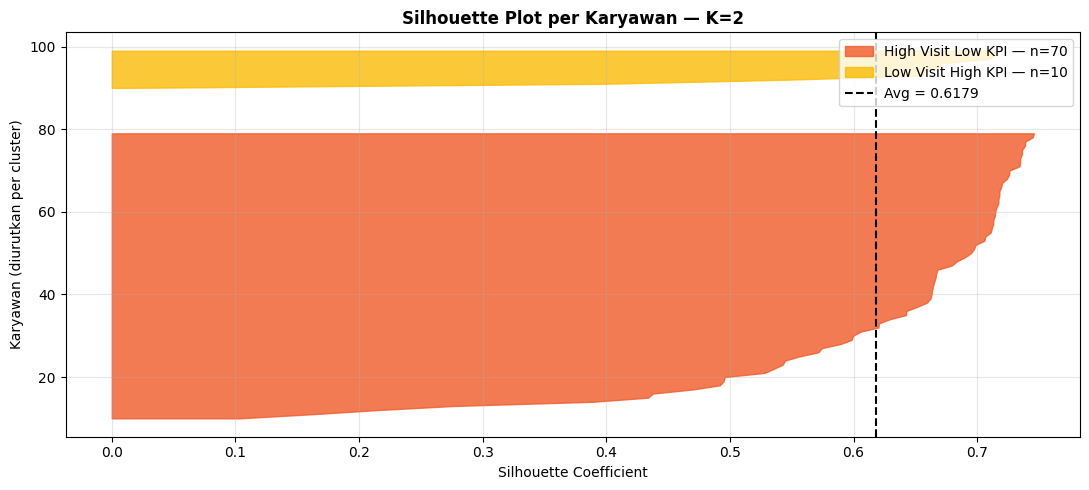


Karyawan dengan Silhouette < 0 (ambigu): 0


In [17]:
sil = silhouette_score(X_scaled, labels_final)
dbi = davies_bouldin_score(X_scaled, labels_final)
ch  = calinski_harabasz_score(X_scaled, labels_final)
sse = kmeans_final.inertia_

if sil >= 0.70:   sil_interp = 'Sangat kuat'
elif sil >= 0.50: sil_interp = 'Cukup baik'
elif sil >= 0.25: sil_interp = 'Lemah'
else:             sil_interp = 'Tidak berarti'

if dbi < 0.5:   dbi_interp = 'Sangat baik'
elif dbi < 1.0: dbi_interp = 'Baik'
elif dbi < 1.5: dbi_interp = 'Cukup'
else:           dbi_interp = 'Buruk'

print('=' * 55)
print(f'     EVALUASI MODEL K-MEANS  (k={BEST_K})')
print('=' * 55)
print(f'  Silhouette Score       : {sil:.4f}  → {sil_interp}')
print(f'  Davies-Bouldin Index   : {dbi:.4f}  → {dbi_interp}')
print(f'  Calinski-Harabasz      : {ch:.2f}')
print(f'  Inertia (SSE)          : {sse:.2f}')
print('=' * 55)
print('  Catatan:')
print('  - Silhouette > 0.50 = cluster cukup terpisah')
print('  - DBI < 1.0         = cluster tidak tumpang tindih')
print('  - CH makin besar    = cluster makin kompak & terpisah')
if excluded:
    print(f'\n    Fitur di-exclude (tidak bervariasi): {excluded}')
    print('     Silhouette mungkin berbeda dibanding run sebelumnya.')
print('=' * 55)

# ── Silhouette per karyawan ──────────────────────────────────
sil_samples = silhouette_samples(X_scaled, labels_final)
df_grouped['silhouette_sample'] = sil_samples

palette = ['#F15A29', '#FBBC05', '#4A90D9', '#22c55e',
           '#a78bfa', '#22d3ee', '#fbbf24', '#fb7185', '#4ade80']

fig, ax = plt.subplots(figsize=(11, 5))
y_lower = 10
for idx, cid in enumerate(ordered_cids):
    lbl     = rank_labels[cid]
    vals    = np.sort(sil_samples[labels_final == cid])
    size    = vals.shape[0]
    y_upper = y_lower + size
    color   = palette[idx % len(palette)]
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals,
                     facecolor=color, edgecolor=color, alpha=0.8,
                     label=f'{lbl} — n={size}')
    y_lower = y_upper + 10

ax.axvline(x=sil, color='black', linestyle='--', linewidth=1.5,
           label=f'Avg = {sil:.4f}')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Karyawan (diurutkan per cluster)')
ax.set_title(f'Silhouette Plot per Karyawan — K={BEST_K}', fontweight='bold')
ax.legend(loc='upper right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('plot_silhouette.png', dpi=150, bbox_inches='tight')
plt.show()

ambiguous = df_grouped[df_grouped['silhouette_sample'] < 0][['Username','cluster_label','silhouette_sample']]
print(f'\nKaryawan dengan Silhouette < 0 (ambigu): {len(ambiguous)}')
if len(ambiguous) > 0:
    print(ambiguous.sort_values('silhouette_sample').head(10).to_string(index=False))

## 10. Analisis Karakteristik Cluster

=== Rata-rata Fitur per Cluster ===
                    visit_count  Facing  Is FIFO/FEFO  Is Price Tag Available
Cluster                                                                      
High Visit Low KPI       8534.4   0.176         0.459                   0.456
Low Visit High KPI       4564.0   0.324         0.849                   0.849

Jumlah karyawan per cluster:
cluster_label
High Visit Low KPI    70
Low Visit High KPI    10
Name: count, dtype: int64


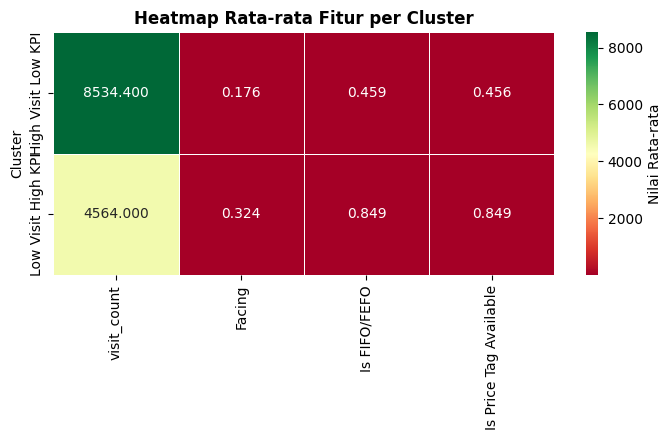

In [18]:
cluster_summary = (
    df_grouped.groupby('cluster_label')[ACTIVE_FEATURES]
              .mean()
              .round(3)
              .reindex(label_order)
)
cluster_summary.index.name = 'Cluster'

print('=== Rata-rata Fitur per Cluster ===')
print(cluster_summary)
print('\nJumlah karyawan per cluster:')
print(df_grouped['cluster_label'].value_counts().reindex(label_order))

plt.figure(figsize=(7, 4.5))
sns.heatmap(cluster_summary, annot=True, fmt='.3f', cmap='RdYlGn',
            linewidths=0.5, cbar_kws={'label': 'Nilai Rata-rata'})
plt.title('Heatmap Rata-rata Fitur per Cluster', fontweight='bold')
plt.tight_layout()
plt.savefig('plot_karakteristik_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

## 10b. Radar Chart — Profil Cluster 4 Dimensi KPI

Visualisasi ini menampilkan **keempat dimensi KPI sekaligus** (Report Product, Facing, FIFO/FEFO, Price Tag) dalam satu grafik radar per cluster — mengatasi keterbatasan scatter plot 2D yang hanya bisa menampilkan 2 fitur sekaligus.

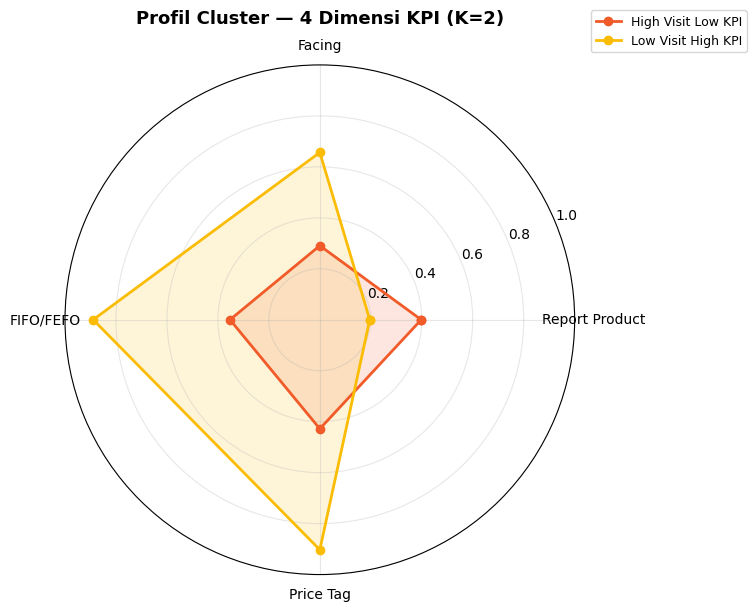

=== Nilai Centroid per Dimensi (skala 0–1) ===
  High Visit Low KPI      : Report Product=0.398, Facing=0.291, FIFO/FEFO=0.353, Price Tag=0.428
  Low Visit High KPI      : Report Product=0.196, Facing=0.657, FIFO/FEFO=0.889, Price Tag=0.903


In [19]:
# ── Radar Chart — Profil Cluster pada Semua Dimensi KPI ───────
# Menggunakan koordinat centroid hasil scaling 0-1 (kmeans_final.cluster_centers_)
# supaya keempat dimensi (Report Product, Facing, FIFO/FEFO, Price Tag) sebanding.

radar_label_map = {
    'visit_count'            : 'Report Product',
    'Facing'                 : 'Facing',
    'Is FIFO/FEFO'           : 'FIFO/FEFO',
    'Is Price Tag Available' : 'Price Tag',
}
labels_radar = [radar_label_map.get(c, c) for c in ACTIVE_FEATURES]
n_vars = len(ACTIVE_FEATURES)

angles = np.linspace(0, 2 * np.pi, n_vars, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

for idx, cid in enumerate(ordered_cids):
    lbl    = rank_labels[cid]
    values = kmeans_final.cluster_centers_[cid].tolist()
    values += values[:1]
    color  = palette[idx % len(palette)]
    ax.plot(angles, values, 'o-', linewidth=2, label=lbl, color=color)
    ax.fill(angles, values, alpha=0.15, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels_radar, fontsize=10)
ax.set_ylim(0, 1)
ax.set_title(f'Profil Cluster — {n_vars} Dimensi KPI (K={BEST_K})',
             fontsize=13, fontweight='bold', pad=30)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.12), fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plot_radar_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

print('=== Nilai Centroid per Dimensi (skala 0–1) ===')
for idx, cid in enumerate(ordered_cids):
    lbl = rank_labels[cid]
    vals = kmeans_final.cluster_centers_[cid]
    detail = ', '.join(f'{radar_label_map.get(c,c).splitlines()[0]}={v:.3f}'
                        for c, v in zip(ACTIVE_FEATURES, vals))
    print(f'  {lbl:<24}: {detail}')

## 11. Scatter Plot 4 Dimensi per Karyawan (Bubble Chart)

Scatter plot sebelumnya (Bab 11) hanya membandingkan 2 KPI (Report Product vs Facing), sehingga tidak merepresentasikan seluruh fitur yang dipakai model. Grafik di bawah ini menampilkan **keempat dimensi KPI sekaligus untuk setiap karyawan** dalam satu scatter plot, dengan encoding:
- **Sumbu X** → Report Product
- **Sumbu Y** → Facing (%)
- **Ukuran titik (bubble size)** → FIFO/FEFO Compliance (%)
- **Warna titik** → Price Tag Compliance (%)
- **Bentuk marker** → Cluster (lingkaran / segitiga, dsb.)

Dengan begitu, satu titik pada grafik ini merepresentasikan satu karyawan dengan informasi dari 4 KPI + label cluster sekaligus — bukan hanya 2 fitur.

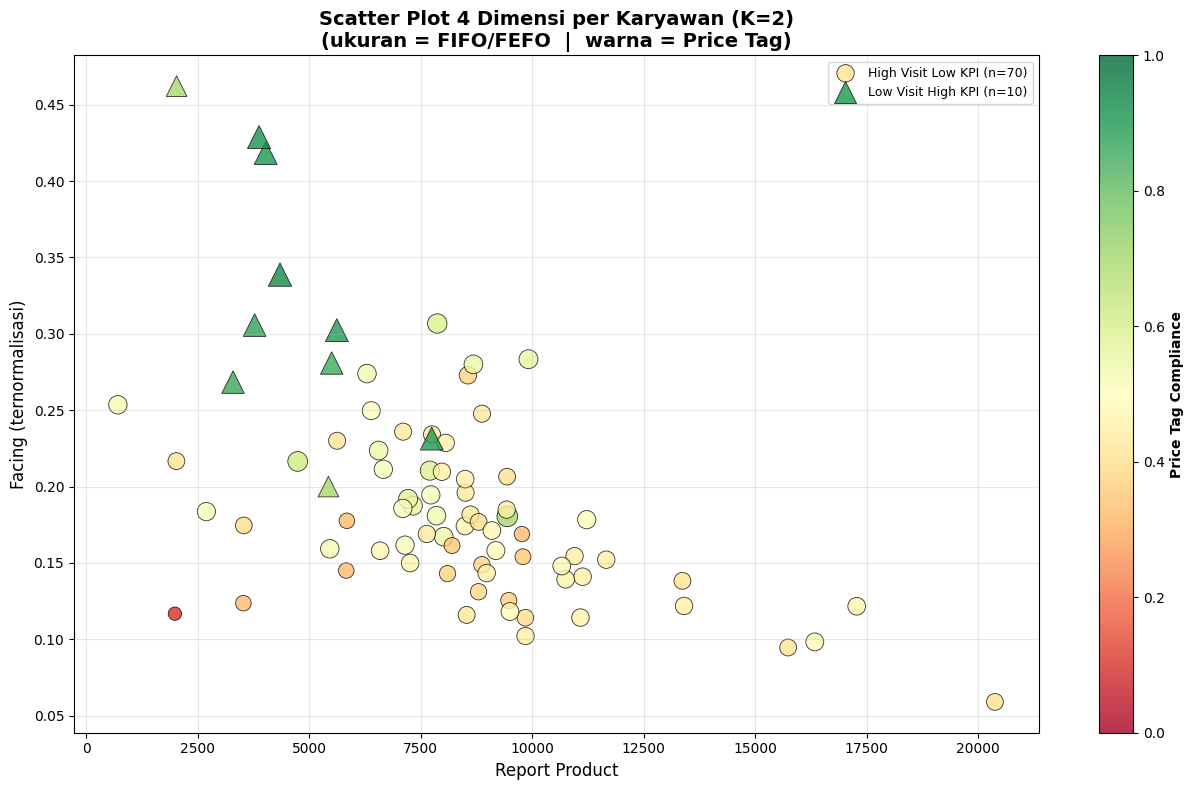

Keterangan encoding:
  Sumbu X       : Report Product
  Sumbu Y       : Facing
  Ukuran titik  : FIFO/FEFO Compliance (makin besar = makin patuh)
  Warna titik   : Price Tag Compliance (merah=rendah, hijau=tinggi)
  Bentuk marker : Cluster label


In [20]:
# ── Scatter Plot 4 Dimensi per Karyawan (Bubble Chart) ────────
# x = Report Product (visit_count), y = Facing,
# size = Is FIFO/FEFO, color = Is Price Tag Available, shape = cluster

has_fifo  = 'Is FIFO/FEFO' in ACTIVE_FEATURES
has_price = 'Is Price Tag Available' in ACTIVE_FEATURES

MARKERS = ['o', '^', 's', 'D', 'P', 'X', 'v', '*']

fig, ax = plt.subplots(figsize=(13, 8))

# Warna: pakai Price Tag jika aktif, kalau tidak fallback ke FIFO, kalau keduanya
# tidak aktif fallback ke warna solid per cluster
color_col = 'Is Price Tag Available' if has_price else ('Is FIFO/FEFO' if has_fifo else None)
size_col  = 'Is FIFO/FEFO' if has_fifo else None

vmin, vmax = (0, 1) if color_col else (None, None)

scatter_ref = None
for idx, lbl in enumerate(label_order):
    subset = df_grouped[df_grouped['cluster_label'] == lbl]
    marker = MARKERS[idx % len(MARKERS)]

    sizes = (40 + subset[size_col] * 260) if size_col else 90

    if color_col:
        sc = ax.scatter(
            subset['visit_count'], subset['Facing'],
            s=sizes, c=subset[color_col], cmap='RdYlGn',
            vmin=vmin, vmax=vmax,
            marker=marker, alpha=0.8,
            edgecolors='black', linewidth=0.6,
            label=f'{lbl} (n={len(subset)})'
        )
        scatter_ref = sc
    else:
        ax.scatter(
            subset['visit_count'], subset['Facing'],
            s=sizes, marker=marker, alpha=0.8,
            color=palette[idx % len(palette)],
            edgecolors='black', linewidth=0.6,
            label=f'{lbl} (n={len(subset)})'
        )

if scatter_ref is not None:
    cbar = plt.colorbar(scatter_ref, ax=ax)
    cbar_title = 'Price Tag Compliance' if has_price else 'FIFO/FEFO Compliance'
    cbar.set_label(cbar_title, fontsize=10, fontweight='bold')

ax.set_xlabel('Report Product', fontsize=12)
ax.set_ylabel('Facing (ternormalisasi)', fontsize=12)
title_extra = []
if size_col:
    title_extra.append('ukuran = FIFO/FEFO')
if color_col:
    title_extra.append(f'warna = {"Price Tag" if has_price else "FIFO/FEFO"}')
extra_txt = '  |  '.join(title_extra)
ax.set_title(f'Scatter Plot 4 Dimensi per Karyawan (K={BEST_K})\n({extra_txt})',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=9, loc='upper right')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('plot_scatter_4dimensi.png', dpi=150, bbox_inches='tight')
plt.show()

print('Keterangan encoding:')
print('  Sumbu X       : Report Product')
print('  Sumbu Y       : Facing')
if size_col:
    print('  Ukuran titik  : FIFO/FEFO Compliance (makin besar = makin patuh)')
if color_col:
    print(f'  Warna titik   : {"Price Tag" if has_price else "FIFO/FEFO"} Compliance (merah=rendah, hijau=tinggi)')
print('  Bentuk marker : Cluster label')

## 11b. Perbandingan Distribusi Tiap KPI Antar Cluster

Visualisasi ini memisahkan **setiap KPI ke dalam grafiknya masing-masing** (4 subplot terpisah), dengan kedua cluster ditampilkan berdampingan (side-by-side) sebagai box plot pada tiap subplot. Ini melengkapi radar chart (10b) dan scatter 4 dimensi (11b) — kalau dua visualisasi sebelumnya menggabungkan 4 KPI dalam satu grafik, visualisasi ini justru memisahkannya per KPI supaya perbedaan distribusi antar cluster terlihat jelas dan mudah diuji secara statistik (median, sebaran IQR, outlier).

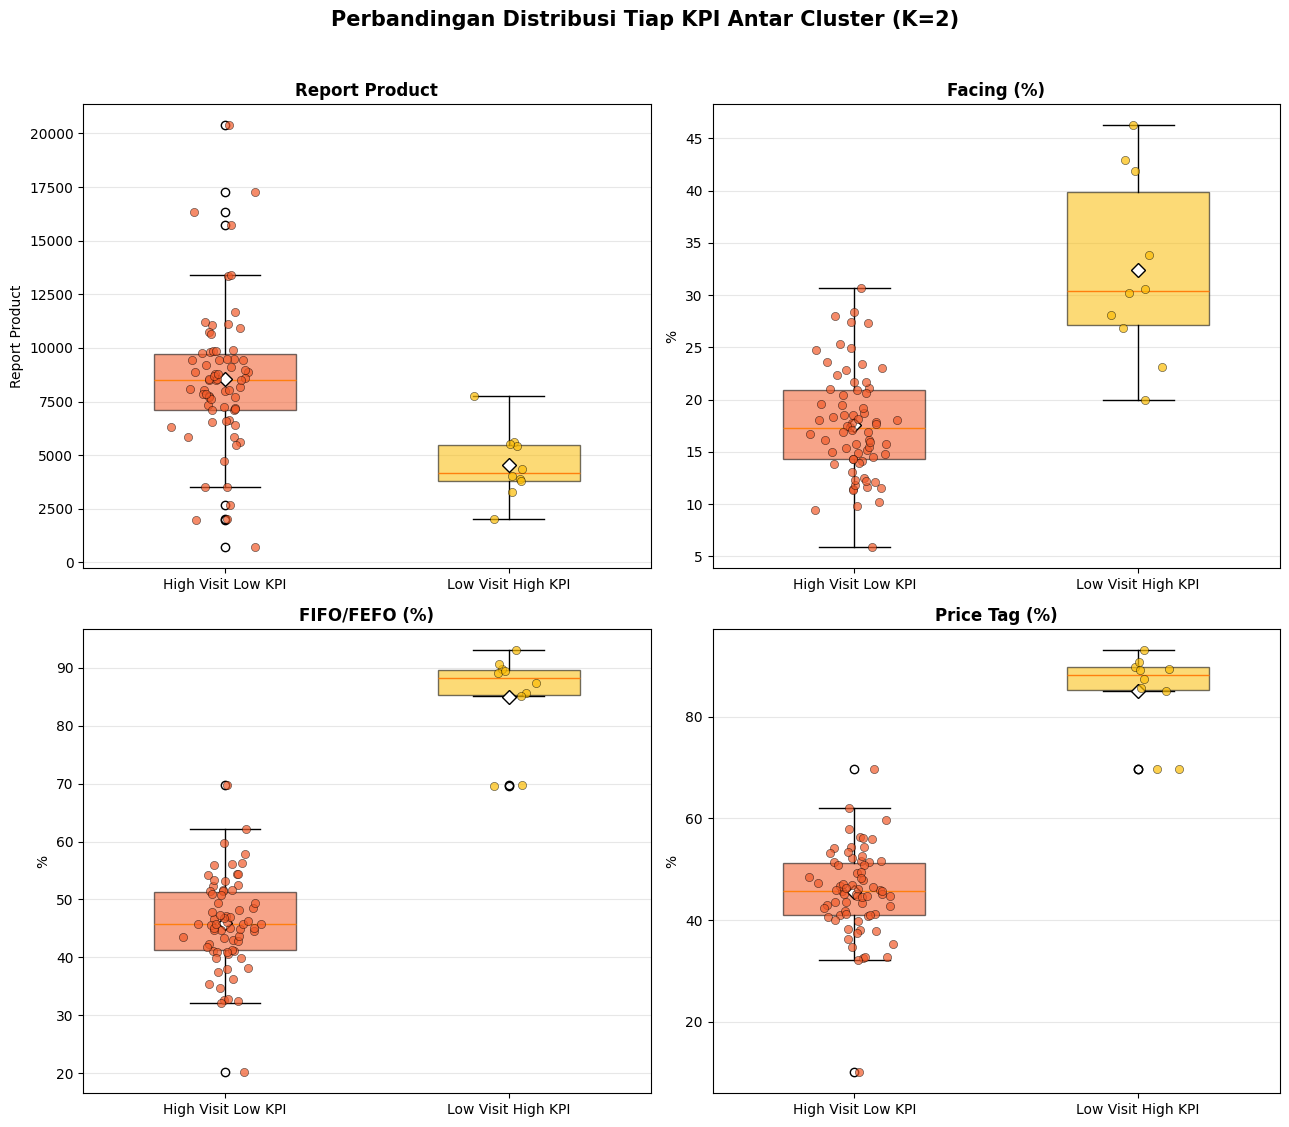

=== Median tiap KPI per Cluster ===

Report Product
  High Visit Low KPI      : median=8501.50  mean=8534.40
  Low Visit High KPI      : median=4184.50  mean=4564.00

Facing (%)
  High Visit Low KPI      : median=17.26  mean=17.61
  Low Visit High KPI      : median=30.41  mean=32.37

FIFO/FEFO (%)
  High Visit Low KPI      : median=45.74  mean=45.85
  Low Visit High KPI      : median=88.25  mean=84.95

Price Tag (%)
  High Visit Low KPI      : median=45.73  mean=45.59
  Low Visit High KPI      : median=88.25  mean=84.95


In [21]:
# ── Box Plot 2x2 — Distribusi Tiap KPI per Cluster ────────────
kpi_display_map = {
    'visit_count'            : ('Report Product', False),
    'Facing'                 : ('Facing (%)',                    True),
    'Is FIFO/FEFO'           : ('FIFO/FEFO (%)',                  True),
    'Is Price Tag Available' : ('Price Tag (%)',                  True),
}

plot_features = [c for c in ['visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']
                 if c in df_grouped.columns]
n_plot = len(plot_features)
n_cols = 2
n_rows = (n_plot + 1) // 2

fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, 5.5 * n_rows))
axes = np.array(axes).reshape(-1)
fig.suptitle(f'Perbandingan Distribusi Tiap KPI Antar Cluster (K={BEST_K})',
             fontsize=15, fontweight='bold', y=1.02)

for i, feat in enumerate(plot_features):
    ax = axes[i]
    title, is_pct = kpi_display_map[feat]

    data_per_cluster = []
    for lbl in label_order:
        vals = df_grouped.loc[df_grouped['cluster_label'] == lbl, feat]
        vals = vals * 100 if is_pct else vals
        data_per_cluster.append(vals.values)

    bp = ax.boxplot(data_per_cluster, labels=label_order, patch_artist=True,
                     widths=0.5, showmeans=True,
                     meanprops=dict(marker='D', markerfacecolor='white',
                                    markeredgecolor='black', markersize=7))

    for idx, box in enumerate(bp['boxes']):
        box.set(facecolor=palette[idx % len(palette)], alpha=0.55, edgecolor='black')

    # overlay titik individu (jitter) supaya sebaran tiap karyawan terlihat
    for idx, vals in enumerate(data_per_cluster):
        jitter_x = np.random.normal(idx + 1, 0.06, size=len(vals))
        ax.scatter(jitter_x, vals, color=palette[idx % len(palette)],
                   edgecolors='black', linewidth=0.4, alpha=0.7, s=35, zorder=3)

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_ylabel('%' if is_pct else 'Report Product')
    ax.grid(axis='y', alpha=0.3)

# kosongkan subplot sisa kalau jumlah fitur ganjil
for j in range(n_plot, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('plot_boxplot_kpi_per_cluster.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Ringkasan statistik median per KPI per cluster ────────────
print('=== Median tiap KPI per Cluster ===')
for feat in plot_features:
    title, is_pct = kpi_display_map[feat]
    print(f'\n{title}')
    for lbl in label_order:
        vals = df_grouped.loc[df_grouped['cluster_label'] == lbl, feat]
        vals = vals * 100 if is_pct else vals
        print(f'  {lbl:<24}: median={vals.median():.2f}  mean={vals.mean():.2f}')

## 12. Heatmap Korelasi Antar Fitur

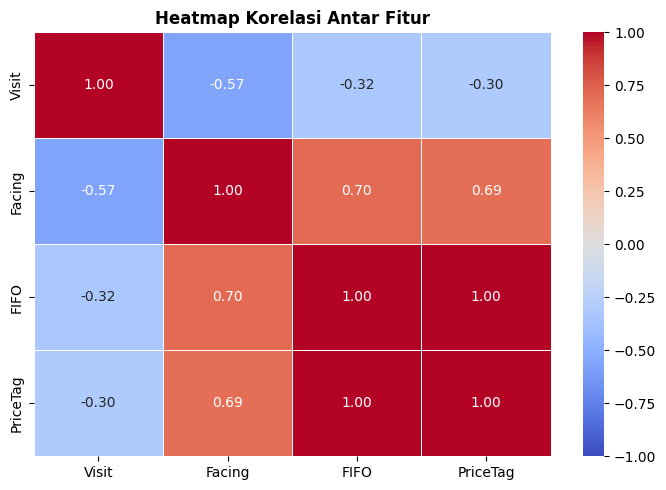

In [22]:
plt.figure(figsize=(7, 5))
corr = df_grouped[ACTIVE_FEATURES].corr()
tick_labels = ['Visit' if c == 'visit_count' else
               'Facing' if c == 'Facing' else
               'FIFO' if 'FIFO' in c else 'PriceTag'
               for c in ACTIVE_FEATURES]
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1,
            xticklabels=tick_labels, yticklabels=tick_labels)
plt.title('Heatmap Korelasi Antar Fitur', fontweight='bold')
plt.tight_layout()
plt.savefig('plot_korelasi.png', dpi=150, bbox_inches='tight')
plt.show()

## 13. Export Hasil & Simpan Model

In [23]:
# ── Gabung employee_info + clustering result ──────────────────
# employee_info sudah berisi: Username, Nama Karyawan, Role, Area, Region,
#                              Nama Store (list), Jumlah Store
final_df = employee_info.merge(df_grouped, on='Username', how='right')
final_df['silhouette_sample'] = final_df['silhouette_sample'].round(4)

# Tambahkan flag ambigu
final_df['sil_flag'] = final_df['silhouette_sample'].apply(
    lambda x: 'ambigu' if x < 0 else 'ok'
)

# Kolom output yang rapi
output_cols = [
    'Username', 'Nama Karyawan', 'Role', 'Area', 'Region',
    'cluster', 'cluster_label',
    'visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available',
    'silhouette_sample', 'sil_flag',
    'Jumlah Store', 'Nama Store',
]
output_cols = [c for c in output_cols if c in final_df.columns]
final_df    = final_df[output_cols]

output_path = f'hasil_clustering_k{BEST_K}.xlsx'
final_df.to_excel(output_path, index=False)
print(f'✅ Hasil disimpan ke: {output_path}')
print(f'   Total baris  : {len(final_df)}')
print(f'   Kolom        : {final_df.columns.tolist()}')
final_df.head(5)

✅ Hasil disimpan ke: hasil_clustering_k2.xlsx
   Total baris  : 80
   Kolom        : ['Username', 'Nama Karyawan', 'Role', 'Area', 'Region', 'cluster', 'cluster_label', 'visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available', 'silhouette_sample', 'sil_flag']


,Username,Nama Karyawan,Role,Area,Region,cluster,cluster_label,visit_count,Facing,Is FIFO/FEFO,Is Price Tag Available,silhouette_sample,sil_flag
0,ID-BA000832,KADEK AGUS SATYA NUGRAHA,MD MM,DENPASAR,BALI NUSRA,0,High Visit Low KPI,15738,0.094548,0.410662,0.410662,0.5895,ok
1,ID-BA0010010,IWAN FAHRUL RIZAL,MD MIX,DENPASAR,BALI NUSRA,0,High Visit Low KPI,20375,0.058896,0.408687,0.408687,0.4700,ok
2,ID-BA001575,NI LUH EKA SEPI ASRINI,MD MIX,DENPASAR,BALI NUSRA,0,High Visit Low KPI,7106,0.235927,0.430200,0.430200,0.6679,ok
3,ID-BA010042,DEDI HERMAWAN,MD MIX,DENPASAR,BALI NUSRA,0,High Visit Low KPI,16336,0.098219,0.484574,0.484574,0.5446,ok
4,ID-BE000230,SISKA ERIANI,MD MIX,BENGKULU,SUMATERA BARAT,0,High Visit Low KPI,11082,0.114149,0.457589,0.457499,0.6949,ok


In [24]:
os.makedirs('models', exist_ok=True)
joblib.dump(kmeans_final, 'models/kmeans_model.pkl')
joblib.dump(scaler,       'models/minmax_scaler.pkl')
print('✅ Model  disimpan ke models/kmeans_model.pkl')
print('✅ Scaler disimpan ke models/minmax_scaler.pkl')

# ── cluster_stats untuk meta ──────────────────────────────────
cluster_stats_dict = {}
for cid in ordered_cids:
    lbl = rank_labels[cid]
    row = cluster_stats.loc[cid]
    cluster_stats_dict[lbl] = {
        'visit_mean' : round(float(row['visit_mean']),  2),
        'kpi_mean'   : round(float(row['kpi_mean']),    4),
    }

meta = {
    'k'                : BEST_K,
    'output_file'      : output_path,
    'active_features'  : ACTIVE_FEATURES,
    'excluded_features': excluded,
    'k_selection'      : {
        'silhouette'        : best_sil_k,
        'davies_bouldin'    : best_dbi_k,
        'calinski_harabasz' : best_ch_k,
        'winner'            : BEST_K,
    },
    'cluster_labels'   : {str(k): v for k, v in rank_labels.items()},
    'label_order'      : label_order,
    'cluster_stats'    : cluster_stats_dict,
    'silhouette_score' : round(sil, 4),
    'davies_bouldin'   : round(dbi, 4),
    'calinski_harabasz': round(ch,  2),
    'inertia'          : round(sse, 2),
    'n_karyawan'       : len(final_df),
}
with open('cluster_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)
print('✅ Metadata disimpan ke cluster_meta.json')
print(json.dumps(meta, indent=2))

✅ Model  disimpan ke models/kmeans_model.pkl
✅ Scaler disimpan ke models/minmax_scaler.pkl
✅ Metadata disimpan ke cluster_meta.json
{
  "k": 2,
  "output_file": "hasil_clustering_k2.xlsx",
  "active_features": [
    "visit_count",
    "Facing",
    "Is FIFO/FEFO",
    "Is Price Tag Available"
  ],
  "excluded_features": [],
  "k_selection": {
    "silhouette": 2,
    "davies_bouldin": 2,
    "calinski_harabasz": 2,
    "winner": 2
  },
  "cluster_labels": {
    "0": "High Visit Low KPI",
    "1": "Low Visit High KPI"
  },
  "label_order": [
    "High Visit Low KPI",
    "Low Visit High KPI"
  ],
  "cluster_stats": {
    "High Visit Low KPI": {
      "visit_mean": 8534.4,
      "kpi_mean": 0.3635
    },
    "Low Visit High KPI": {
      "visit_mean": 4564.0,
      "kpi_mean": 0.6742
    }
  },
  "silhouette_score": 0.6179,
  "davies_bouldin": 0.5409,
  "calinski_harabasz": 89.61,
  "inertia": 5.24,
  "n_karyawan": 80
}


## 14. Ringkasan Akhir

In [25]:
print('=' * 60)
print(f'     RINGKASAN HASIL CLUSTERING K={BEST_K}')
print('=' * 60)
print(f'  Total karyawan dianalisis : {len(final_df)}')
print(f'  Fitur aktif               : {ACTIVE_FEATURES}')
if excluded:
    print(f'  Fitur di-exclude          : {excluded}')
print()
for lbl in label_order:
    n_k  = (final_df['cluster_label'] == lbl).sum()
    n_amb = ((final_df['cluster_label'] == lbl) & (final_df['sil_flag'] == 'ambigu')).sum()
    print(f'  {lbl:<24}: {n_k:>4} karyawan  ({n_amb} ambigu)')
print()
print('  --- Evaluasi Model ---')
print(f'  Silhouette Score       : {sil:.4f}  → {sil_interp}')
print(f'  Davies-Bouldin Index   : {dbi:.4f}  → {dbi_interp}')
print(f'  Calinski-Harabasz      : {ch:.2f}')
print(f'  Inertia (SSE)          : {sse:.2f}')
print()
print('  --- Karakteristik Cluster ---')
for lbl in label_order:
    sub = df_grouped[df_grouped['cluster_label'] == lbl]
    kpi_vals = []
    for c in kpi_active:
        kpi_vals.append(f'{c.split()[0]}={sub[c].mean()*100:.1f}%')
    print(f'  [{lbl:<22}] visit={sub["visit_count"].mean():.1f} | '
          + ' | '.join(kpi_vals))
print('=' * 60)

     RINGKASAN HASIL CLUSTERING K=2
  Total karyawan dianalisis : 80
  Fitur aktif               : ['visit_count', 'Facing', 'Is FIFO/FEFO', 'Is Price Tag Available']

  High Visit Low KPI      :   70 karyawan  (0 ambigu)
  Low Visit High KPI      :   10 karyawan  (0 ambigu)

  --- Evaluasi Model ---
  Silhouette Score       : 0.6179  → Cukup baik
  Davies-Bouldin Index   : 0.5409  → Baik
  Calinski-Harabasz      : 89.61
  Inertia (SSE)          : 5.24

  --- Karakteristik Cluster ---
  [High Visit Low KPI    ] visit=8534.4 | Facing=17.6% | Is=45.9% | Is=45.6%
  [Low Visit High KPI    ] visit=4564.0 | Facing=32.4% | Is=84.9% | Is=84.9%
